# Week (2) Module C: ML Foundations, Data Preparation & Feature Engineering
**Course:** Statistics and Machine Learning

---

### Module Contributor(s)
| Full Name | Role |
|---|---|
| `_______________` | `_______________` |
| `_______________` | `_______________` |

---

### About this Module
This module covers **Tasks 7, 8, and 9** of the Week (2) practical.
Your outputs will be merged with **Modules A, B, and D into the group's final notebook**.

**Dataset:** Pima Indians Diabetes → DOI: https://www.openml.org/d/37

| Feature | Description |
|---|---|
| `Pregnancies` | Number of pregnancies |
| `Glucose` | Plasma glucose concentration |
| `BloodPressure` | Diastolic blood pressure (mm Hg) |
| `SkinThickness` | Triceps skin fold thickness (mm) |
| `Insulin` | 2-hour serum insulin (mu U/ml) |
| `BMI` | Body mass index |
| `DiabetesPedigreeFunction` | Genetic risk score |
| `Age` | Age in years |
| `Outcome` | 0 = Non-diabetic, 1 = Diabetic |

---

**Background: Week 2 Day 1 lecture recap:**

Machine Learning is a field of AI where computers learn patterns from data to make predictions without being explicitly programmed for every rule. Before any model can be trained, the data must be prepared carefully.

> - **Types of ML:** *Supervised* (labelled data → learn input–output mapping), *Unsupervised* (no labels → find hidden patterns), *Reinforcement* (agent learns via rewards/penalties).
> - **ML Workflow:** Problem Definition → Data Collection → Preprocessing → Feature Selection → Data Splitting → Model Training → Evaluation → Deployment.
> - **Missing values:** zeros in clinical columns are impossible (e.g. Glucose=0) and must be treated as NaN before imputation.
> - **Noise vs Outliers:** noise = small random errors affecting many points; outliers = rare extreme values affecting a few points strongly.
> - **Feature Engineering:** creates new variables (ratios, interactions, bins) that better capture the underlying pattern.
> - **Feature Scaling:** standardisation (z-score) and normalisation (min–max) bring features to the same scale, preventing large-magnitude features from dominating the model.

---
> Cells marked `# TODO` require code. Cells marked `✍️` require a written response.

---
# Task 7: Types of Machine Learning & Identifying the Task
Before choosing a model, you must identify what *type* of ML problem you are solving. The Diabetes dataset can be approached in multiple ways.

> **Goal:** Classify the Diabetes prediction task into the correct ML category, define X (features) and y (target), and inspect the class balance.

In [73]:
# ── Task 7 Setup (do not modify) ──────────────────────────────────────────────

# pandas: DataFrames, reading CSV, groupby, filtering
import pandas as pd

# numpy: numerical arrays and mathematical operations
import numpy as np

# matplotlib + seaborn: plotting
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

print(f'Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns')


Dataset loaded: 768 rows x 10 columns


In [74]:
# Provided: classify the ML problem type and define X and y

# --- ML Problem Classification ---
# The lecture defined three types:
#   Supervised     → labelled data, learn input→output (classification or regression)
#   Unsupervised   → no labels, discover patterns (clustering, dimensionality reduction)
#   Reinforcement  → agent learns via rewards/penalties (game AI, robotics)
#
# The Diabetes dataset HAS labels (Outcome: 0/1, whether the patient has diabetes).
# We want to PREDICT the label from the other columns.
# → This is SUPERVISED LEARNING, specifically BINARY CLASSIFICATION.

print('ML Problem Type: Supervised Learning, Binary Classification')
print('  Reason: We have labelled examples (Outcome = 0 or 1) and want to')
print('          predict the label for new, unseen patients.')
print()

# --- Define features (X) and target (y) ---
# X contains all input columns: the information available at prediction time.
# y contains the label we want to predict.
# We exclude 'DiabetesStatus' because it is derived from Outcome: not an independent feature.
FEATURE_COLS = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
                'Insulin','BMI','DiabetesPedigreeFunction','Age']

X = df[FEATURE_COLS]   # shape: (768, 8) the input features
y = df['Outcome']      # shape: (768,)   the binary target label

print(f'X shape: {X.shape}  (rows=patients, cols=features)')
print(f'y shape: {y.shape}  (0=Non-Diabetic, 1=Diabetic)')
print(f'\nFeatures used: {FEATURE_COLS}')


ML Problem Type: Supervised Learning, Binary Classification
  Reason: We have labelled examples (Outcome = 0 or 1) and want to
          predict the label for new, unseen patients.

X shape: (768, 8)  (rows=patients, cols=features)
y shape: (768,)  (0=Non-Diabetic, 1=Diabetic)

Features used: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [75]:
# TODO: Check and visualise the class balance of the target variable y.
#
# Class imbalance matters: if 90% of patients are Non-Diabetic, a model that always
# predicts 'Non-Diabetic' will achieve 90% accuracy without learning anything.
#
# Steps:
#   1. Print the count of each class: y.value_counts()
#   2. Print the percentage split: y.value_counts(normalize=True) * 100, rounded to 1 dp.
#   3. Create a bar chart showing the count of Diabetic vs Non-Diabetic patients.
#      Use df['DiabetesStatus'].value_counts().plot(kind='bar', ...).
#      Colour bars: Non-Diabetic='steelblue', Diabetic='tomato'.
#   4. Annotate each bar with its count and percentage.
#   5. Add a title: 'Class Balance: Diabetic vs Non-Diabetic' and rotate x-axis labels.

# YOUR CODE HERE


In [76]:
# TODO: Complete the ML workflow classification table.
#
# Replace each '???' with the correct answer for the Diabetes dataset.
# The table maps the 10-step ML workflow from the lecture to this specific project. 
# This is only an illustrative example (no actual training is needed at the moment).

workflow = {
    'Step 1 Problem Definition':  {'Our answer': '???'},
    # e.g. 'Predict whether a patient has diabetes (binary classification)'

    'Step 2 Data Collection':     {'Our answer': '???'},
    # e.g. 'Pima Indians Diabetes dataset from openml.org (768 patients)'

    'Step 3 Data Preprocessing':  {'Our answer': '???'},
    # e.g. 'Replace impossible zeros with NaN, then impute'

    'Step 4 Feature Selection':   {'Our answer': '???'},
    # e.g. 'All 8 clinical features; remove DiabetesStatus (derived column)'

    'Step 5 Data Splitting':      {'Our answer': '???'},
    # e.g. '80% train / 20% test, stratified on Outcome'

    'Step 6 Model Selection':     {'Our answer': '???'},
    # e.g. 'To be decided in Module D (linear/logistic regression)'

    'Step 7 Model Training':      {'Our answer': '???'},
    # e.g. 'Fit model on training set only'

    'Step 8 Evaluation':          {'Our answer': '???'},
    # e.g. 'Assess on test set using MAE/MSE/R² (regression) or accuracy (classification)'

    'Step 9 Hyperparameter Tuning': {'Our answer': '???'},
    # e.g. 'Cross-validation to optimise regularisation strength'

    'Step 10 Deployment':         {'Our answer': '???'},
    # e.g. 'Serve via API so clinicians can input patient values and get a risk score'
}

workflow_df = pd.DataFrame(workflow).T
print(workflow_df.to_string())


                             Our answer
Step 1 Problem Definition           ???
Step 2 Data Collection              ???
Step 3 Data Preprocessing           ???
Step 4 Feature Selection            ???
Step 5 Data Splitting               ???
Step 6 Model Selection              ???
Step 7 Model Training               ???
Step 8 Evaluation                   ???
Step 9 Hyperparameter Tuning        ???
Step 10 Deployment                  ???


### ✍️ Interpretation: Task 7

1. The dataset has roughly 65% Non-Diabetic and 35% Diabetic patients. Is this considered balanced or imbalanced? Why does this matter when choosing an evaluation metric?
2. Could the Diabetes dataset also be used for *unsupervised* learning? Describe one unsupervised task you could perform with it and what you might discover.
3. The lecture showed the difference between traditional programming and ML: 'Data + Rules → Output' vs 'Data + Output → Rules'. Apply this distinction to the Diabetes prediction problem.

> *Your answer here:*

---
# Task 8: Handling Missing Values, Noise & Outliers
Data preprocessing is not optional, it determines whether a model learns from real signals or from artefacts. This task continues directly from Task 7 above, using the same X/y setup.

> **Goal:** Impute missing values (disguised as zeros) using mean and median imputation, compare the strategies, and detect outliers using the IQR method.

In [77]:
# ── Task 8 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'

# Load as 'raw', this is the unmodified original with impossible zeros.
# We keep this separate so that we can always compare raw vs cleaned results.
df_raw = pd.read_csv(URL)

# These five columns contain clinically impossible zeros, they represent missing measurements.
# 'Pregnancies' and 'Age' can legitimately be zero so they are NOT in this list.
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print('Ready')


Ready


In [78]:
# Provided: replace zeros with NaN, then apply MEAN imputation

# Step 1: Create a clean copy, never overwrite the raw dataset.
#         .copy() ensures df_mean and df_raw are independent objects in memory.
#         Without .copy(), modifying df_mean would also modify df_raw.
df_mean = df_raw.copy()

# Step 2: Replace impossible zeros with NaN.
#         .replace(0, np.nan) converts every 0 in the selected columns to NaN.
df_mean[SUSPECT_COLS] = df_mean[SUSPECT_COLS].replace(0, np.nan)

# Step 3: Fill NaN with the column mean (mean imputation).
#         .fillna(df_mean[SUSPECT_COLS].mean()) computes each column's mean
#         (ignoring NaN) and fills missing entries with it.
col_means = df_mean[SUSPECT_COLS].mean()   # compute means BEFORE filling
df_mean[SUSPECT_COLS] = df_mean[SUSPECT_COLS].fillna(col_means)

# Verify: NaN count should now be zero in all suspect columns.
print('--- After mean imputation ---')
print('Remaining NaN values:')
print(df_mean[SUSPECT_COLS].isnull().sum())
print()

# Compare means before and after.
print('Mean values (raw vs mean-imputed):')
comparison = pd.DataFrame({
    'Raw mean':  df_raw[SUSPECT_COLS].replace(0, np.nan).mean(),
    'After mean imputation': df_mean[SUSPECT_COLS].mean()
}).round(2)
print(comparison)


--- After mean imputation ---
Remaining NaN values:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Mean values (raw vs mean-imputed):
               Raw mean  After mean imputation
Glucose          121.69                 121.69
BloodPressure     72.41                  72.41
SkinThickness     29.15                  29.15
Insulin          155.55                 155.55
BMI               32.46                  32.46


In [79]:
# TODO: Create a second cleaned version using MEDIAN imputation (df_median).
#
# Why median instead of mean?
# Columns like Insulin are heavily right-skewed (many zeros, some very high values).
# The mean is pulled upward by large outliers, so median imputation is more robust.
#
# Steps:
#   1. Create df_median = df_raw.copy().
#   2. Replace zeros in SUSPECT_COLS with NaN.
#   3. Compute the median of each SUSPECT_COL (ignoring NaN): df_median[SUSPECT_COLS].median().
#   4. Fill NaN with the computed medians.
#   5. Build a comparison DataFrame with columns:
#      'Raw mean' | 'Mean imputed' | 'Median imputed'
#      for each of the five SUSPECT_COLS. Round to 2 dp.
#   6. Print the table.

# YOUR CODE HERE
df_median = df_raw.copy()
df_mean = df_raw.copy()

# Step 2: Replace impossible zeros with NaN.
#         .replace(0, np.nan) converts every 0 in the selected columns to NaN.
df_median[SUSPECT_COLS] = df_median[SUSPECT_COLS].replace(0, np.nan)
df_mean[SUSPECT_COLS] = df_mean[SUSPECT_COLS].replace(0, np.nan)
# Step 3: Fill NaN with the column mean (mean imputation).
#         .fillna(df_mean[SUSPECT_COLS].mean()) computes each column's mean
#         (ignoring NaN) and fills missing entries with it.
col_medians = df_median[SUSPECT_COLS].median()   # compute means BEFORE filling
col_means = df_mean[SUSPECT_COLS].mean()
df_median[SUSPECT_COLS] = df_median[SUSPECT_COLS].fillna(col_medians)
df_mean[SUSPECT_COLS] = df_mean[SUSPECT_COLS].fillna(col_means)
# Verify: NaN count should now be zero in all suspect columns.
print('--- After mean imputation ---')
print('Remaining NaN values:')
print(df_median[SUSPECT_COLS].isnull().sum())
print()

# Compare means before and after.
print('Mean values (raw vs mean-imputed):')
comparison = pd.DataFrame({
    'Raw mean':  df_raw[SUSPECT_COLS].replace(0, np.nan).mean(),
    'After median imputation': df_median[SUSPECT_COLS].median(),
    'After mean imputation': df_mean[SUSPECT_COLS].mean()
}).round(2)
print(comparison)


--- After mean imputation ---
Remaining NaN values:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Mean values (raw vs mean-imputed):
               Raw mean  After median imputation  After mean imputation
Glucose          121.69                    117.0                 121.69
BloodPressure     72.41                     72.0                  72.41
SkinThickness     29.15                     29.0                  29.15
Insulin          155.55                    125.0                 155.55
BMI               32.46                     32.3                  32.46


--- IQR Outlier Detection Summary ---
      Feature     Q1     Q3   IQR  Lower fence  Upper fence  Outlier count  Outlier %
      Glucose  99.75 140.25 40.50        39.00       201.00              0       0.00
BloodPressure  64.00  80.00 16.00        40.00       104.00             14       1.82
SkinThickness  25.00  32.00  7.00        14.50        42.50             87      11.33
      Insulin 121.50 155.55 34.05        70.43       206.62            164      21.35
          BMI  27.50  36.60  9.10        13.85        50.25              8       1.04


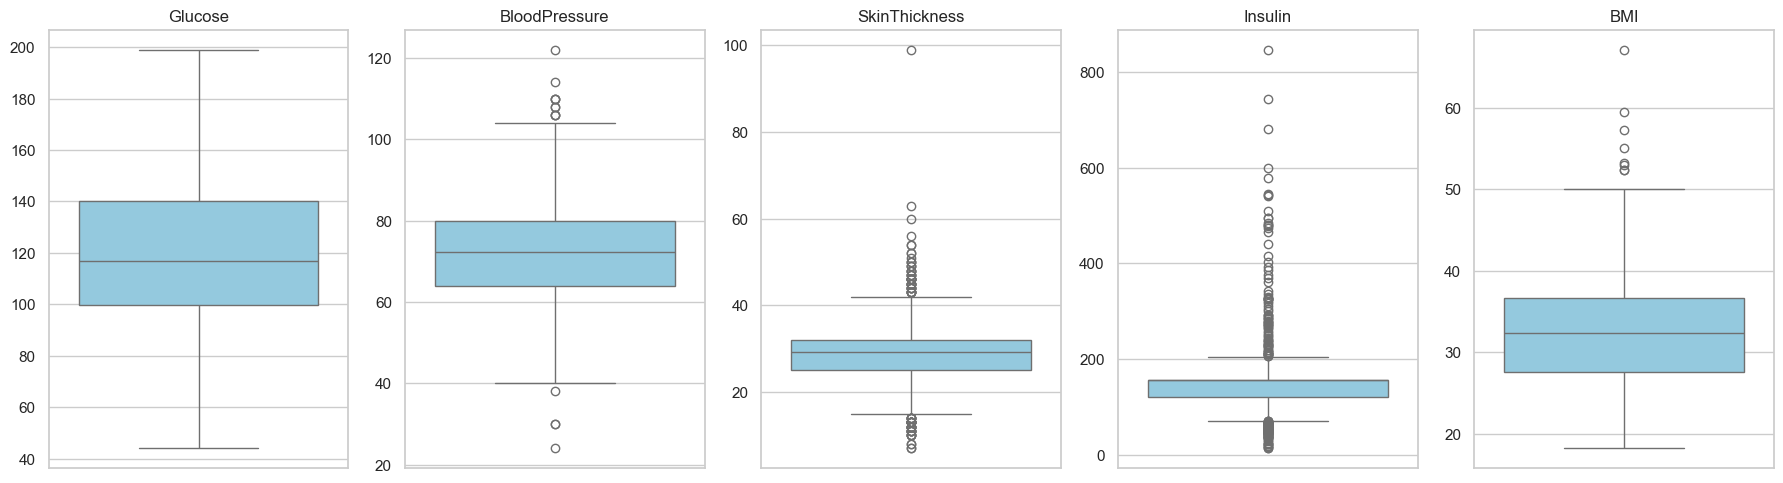

In [80]:
# TODO: Detect outliers in df_mean using the IQR (Interquartile Range) method.
#
# The IQR method defines outliers as values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.
# This is the same rule used to draw whiskers in a boxplot.
#
# Steps:
#   1. For each column in SUSPECT_COLS:
#        a. Compute Q1 = 25th percentile and Q3 = 75th percentile.
#        b. Compute IQR = Q3 - Q1.
#        c. Define lower_fence = Q1 - 1.5 * IQR and upper_fence = Q3 + 1.5 * IQR.
#        d. Count outliers: rows where the value < lower_fence or > upper_fence.
#        e. Compute outlier percentage = count / len(df_mean) * 100.
#        f. Append a dict {Feature, Q1, Q3, IQR, Lower fence, Upper fence,
#                          Outlier count, Outlier %} to a list.
#   2. Create a DataFrame and print it rounded to 2 dp.
#   3. Create a boxplot grid: plt.subplots(1, len(SUSPECT_COLS)) showing all five columns.
#      (Boxplots automatically display outliers as individual points.)

# YOUR CODE HERE

# Step 1: Create an empty list to store results
records = []

# Loop through each suspect column
for feature in SUSPECT_COLS:

    # Calculate quartiles
    Q1 = df_mean[feature].quantile(0.25)
    Q3 = df_mean[feature].quantile(0.75)

    # Calculate IQR
    IQR = Q3 - Q1

    # Calculate lower and upper fences
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = df_mean[
        (df_mean[feature] < lower_fence) |
        (df_mean[feature] > upper_fence)
    ]

    # Count outliers
    outlier_count = len(outliers)

    # Calculate percentage
    outlier_percent = (outlier_count / len(df_mean)) * 100

    # Store results
    records.append({
        'Feature': feature,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower fence': lower_fence,
        'Upper fence': upper_fence,
        'Outlier count': outlier_count,
        'Outlier %': outlier_percent
    })

# Step 2: Create a DataFrame
outlier_table = pd.DataFrame(records)

# Print rounded results
print('--- IQR Outlier Detection Summary ---')
print(outlier_table.round(2).to_string(index=False))

# Step 3: Create boxplot grid
fig, axes = plt.subplots(1, len(SUSPECT_COLS), figsize=(18, 5))

for ax, feature in zip(axes, SUSPECT_COLS):
    sns.boxplot(y=df_mean[feature], ax=ax, color='skyblue')
    ax.set_title(feature)
    ax.set_xlabel('')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

### ✍️ Interpretation: Task 8

1. For which column did mean vs median imputation produce the largest difference? Explain WHY skewed distributions cause mean and median to diverge.
2. After imputation, which column has the most outliers by the IQR rule? Should you automatically remove these outliers? What would you lose by doing so?
3. The lecture distinguished noise (random errors affecting many points) from outliers (extreme values affecting a few points strongly). Looking at the boxplots, are the extreme Insulin values more likely to be noise or meaningful outliers? Justify your answer.

> *Your answer here:*
1. For Insulin. Skewed distributions cause mean and median to diverge because the mean is directly influenced by extreme outliers, distorting it's value
2. Insulin has the most outliers. 

---
# Task 9: Feature Engineering & Feature Scaling
Raw features are not always the best representation for a model. Feature engineering creates new variables that capture domain knowledge; feature scaling ensures all features contribute on an equal footing.

> **Goal:** Create three medically motivated new features, then apply both standardisation (z-score) and normalisation (min–max) to all numeric features, and compare the results.

In [81]:
# ── Task 9 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
# StandardScaler: standardisation (z-score) transforms to mean=0, std=1
# MinMaxScaler:   normalisation (min-max)   transforms to range [0, 1]

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df_raw = pd.read_csv(URL)

# Start from a clean dataset: replace impossible zeros with NaN, then median-impute.
# We use median imputation (more robust to skew) as established in Task 8.
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df = df_raw.copy()
df[SUSPECT_COLS] = df[SUSPECT_COLS].replace(0, np.nan)
df[SUSPECT_COLS] = df[SUSPECT_COLS].fillna(df[SUSPECT_COLS].median())

print('Ready (zeros replaced by NaN and median-imputed)')


Ready (zeros replaced by NaN and median-imputed)


In [82]:
# Provided: create two medically motivated engineered features

# --- Engineered Feature 1: Glucose-to-Insulin Ratio ---
# In diabetes medicine, the ratio of blood glucose to insulin levels indicates
# insulin resistance, a high ratio suggests the body is producing insulin but
# not responding to it effectively. A ratio is sometimes more informative
# than either value alone.
df['Glucose_Insulin_Ratio'] = df['Glucose'] / df['Insulin']

# --- Engineered Feature 2: Age Group (binning) ---
# Converting a continuous variable into categorical bins can help models capture
# non-linear effects: the risk of Type 2 diabetes increases sharply with age.
# pd.cut() divides Age into three labelled intervals.
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[20, 35, 50, 82],
    labels=['Young', 'Middle', 'Senior'],
    right=True
)

print('New features added: Glucose_Insulin_Ratio, AgeGroup')
print(df[['Glucose', 'Insulin', 'Glucose_Insulin_Ratio', 'Age', 'AgeGroup']].head(5))
print(f'\nGlucose_Insulin_Ratio, mean: {df["Glucose_Insulin_Ratio"].mean():.3f}, '
      f'std: {df["Glucose_Insulin_Ratio"].std():.3f}')


New features added: Glucose_Insulin_Ratio, AgeGroup
   Glucose  Insulin  Glucose_Insulin_Ratio  Age AgeGroup
0    148.0    125.0               1.184000   50   Middle
1     85.0    125.0               0.680000   31    Young
2    183.0    125.0               1.464000   32    Young
3     89.0     94.0               0.946809   21    Young
4    137.0    168.0               0.815476   33    Young

Glucose_Insulin_Ratio, mean: 1.068, std: 0.721


BMI_Age_Interaction, mean: 1080.9067708333334 
BMI_Age_Interaction, median: 987.25 
BMI_Age_Interaction, std: 437.8139857381695 


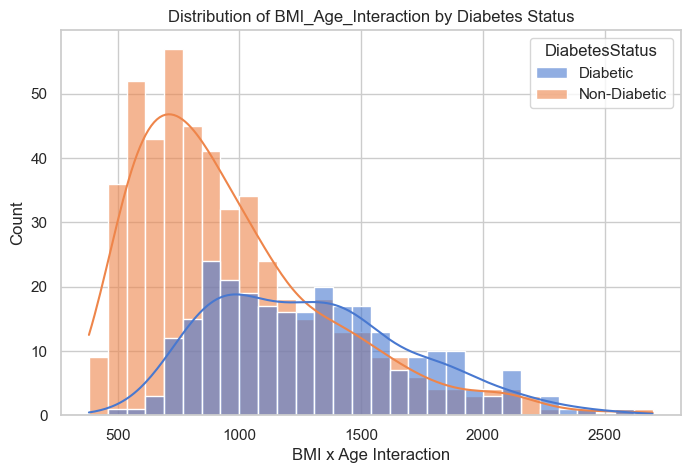

   AgeGroup_Young  AgeGroup_Middle  AgeGroup_Senior
0           False             True            False
1            True            False            False
2            True            False            False


In [83]:
# TODO: Create one more engineered feature and encode the categorical AgeGroup column.
#
# --- Part A: New engineered feature ---
# Create 'BMI_Age_Interaction' = BMI * Age.
# Rationale from the lecture: interaction features capture how two variables
# combine older patients with high BMI may face compounded diabetes risk
# that neither BMI nor Age captures alone.
#
# Steps:
#   1. Compute df['BMI_Age_Interaction'] = df['BMI'] * df['Age'].
#   2. Print the mean, median, and std of the new column.
#   3. Plot a histogram of 'BMI_Age_Interaction' coloured by DiabetesStatus.
#      (First add DiabetesStatus: df['DiabetesStatus'] = df['Outcome'].map({0:'Non-Diabetic',1:'Diabetic'}))
#
# --- Part B: One-hot encode AgeGroup ---
# Machine learning models require numeric inputs, categorical strings must be
# converted. One-hot encoding creates one binary column per category.
# For example: AgeGroup='Young' → AgeGroup_Young=1, AgeGroup_Middle=0, AgeGroup_Senior=0.
#
# Steps:
#   1. Use pd.get_dummies(df['AgeGroup'], prefix='AgeGroup') to create binary columns.
#      Store the result as age_dummies.
#   2. Use pd.concat([df, age_dummies], axis=1) to attach the new columns.
#   3. Drop the original 'AgeGroup' column (it is now redundant).
#   4. Print the column names and the first 3 rows of the new binary columns.

# YOUR CODE HERE
BMI_Age_Interaction = df['BMI'] * df['Age']
print(f'BMI_Age_Interaction, mean: {BMI_Age_Interaction.mean()} ')
print(f'BMI_Age_Interaction, median: {BMI_Age_Interaction.median()} ')
print(f'BMI_Age_Interaction, std: {BMI_Age_Interaction.std()} ')
df["DiabetesStatus"] = df["Outcome"].map({0: "Non-Diabetic",1: "Diabetic"})
plt.figure(figsize=(8, 5))

df['BMI_Age_Interaction'] = BMI_Age_Interaction

# Plot it
sns.histplot(
    data=df,
    x='BMI_Age_Interaction',
    hue='DiabetesStatus',
    bins=30,
    kde=True,
    alpha=0.6
)

plt.title("Distribution of BMI_Age_Interaction by Diabetes Status")
plt.xlabel("BMI x Age Interaction")
plt.ylabel("Count")
plt.show()

age_dummies = pd.get_dummies(df['AgeGroup'], prefix='AgeGroup')
df = pd.concat([df, age_dummies], axis=1)
df.drop(columns=['AgeGroup'], inplace=True)
print(df[['AgeGroup_Young', 'AgeGroup_Middle', 'AgeGroup_Senior']].head(3))


--- Scaling Comparison ---
                          Raw mean  Raw std  Std mean  Std std  MinMax min  \
Pregnancies                  3.845    3.370      -0.0    1.001         0.0   
Glucose                    121.656   30.438       0.0    1.001         0.0   
BloodPressure               72.387   12.097       0.0    1.001         0.0   
SkinThickness               29.108    8.791      -0.0    1.001         0.0   
Insulin                    140.672   86.383       0.0    1.001         0.0   
BMI                         32.455    6.875       0.0    1.001         0.0   
DiabetesPedigreeFunction     0.472    0.331       0.0    1.001         0.0   
Age                         33.241   11.760       0.0    1.001         0.0   
Glucose_Insulin_Ratio        1.068    0.721       0.0    1.001         0.0   
BMI_Age_Interaction       1080.907  437.814      -0.0    1.001         0.0   

                          MinMax max  
Pregnancies                      1.0  
Glucose                          1.0

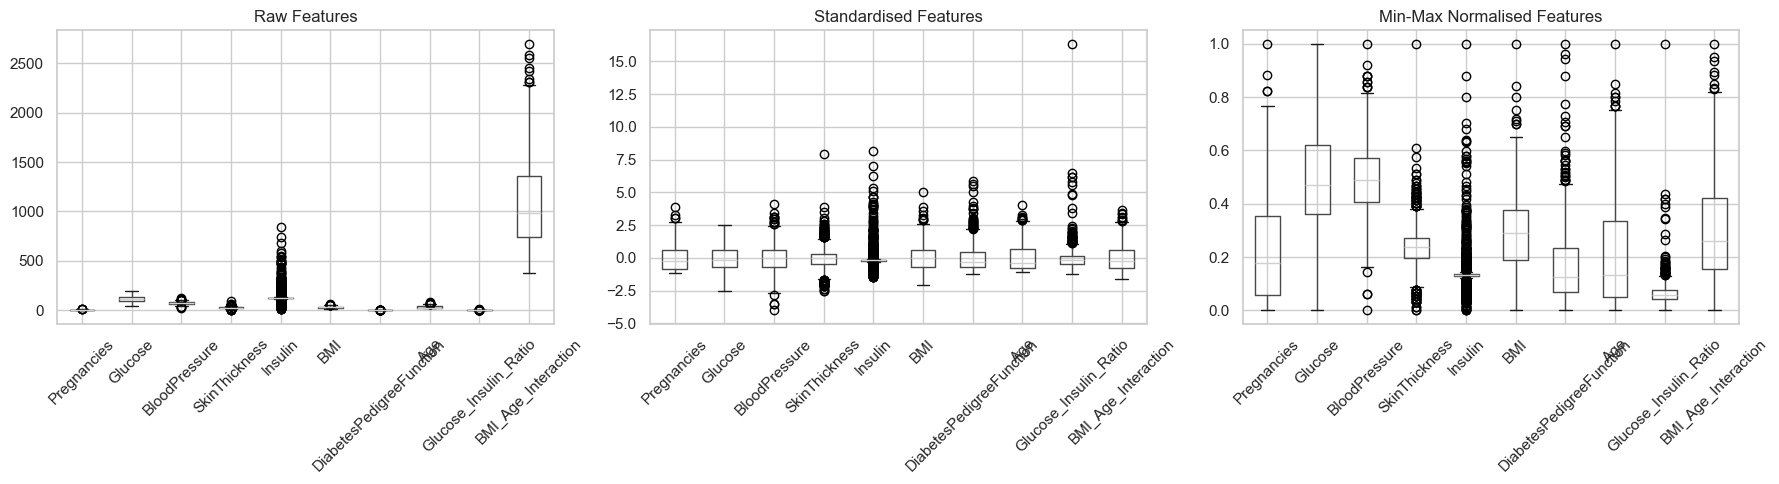

In [84]:
# TODO: Apply Standardisation and Normalisation to the numeric features.
#
# Why scale?
# Features like Insulin (range 0–846) and BloodPressure (range 24–122) are on
# completely different scales. Distance-based models (like KNN) and gradient-based
# optimisers will be dominated by large-scale features unless we normalise.
#
# Standardisation (z-score):  z = (x - mean) / std   → result has mean=0, std=1
#                              Best when data is approximately Normal.
# Normalisation (min-max):     x' = (x - min) / (max - min)  → result in [0, 1]
#                              Best when the range is bounded and known.
#
# Steps:
#   1. Define SCALE_COLS = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
#                            'Insulin','BMI','DiabetesPedigreeFunction','Age',
#                            'Glucose_Insulin_Ratio','BMI_Age_Interaction']
#      (Use the clean df with engineered features from above; drop AgeGroup binary cols.)
#
#   2. Apply StandardScaler:
#        scaler_std = StandardScaler()
#        X_std = pd.DataFrame(scaler_std.fit_transform(df[SCALE_COLS]),
#                             columns=SCALE_COLS)
#
#   3. Apply MinMaxScaler similarly → X_minmax.
#
#   4. Print a comparison table:
#      Column | Raw mean | Raw std | Std mean | Std std | MinMax min | MinMax max
#      Round all to 3 dp.
#
#   5. Create a 3-panel figure (plt.subplots(1, 3, figsize=(15, 4))):
#      Panel 1: Boxplot of raw features for SCALE_COLS.
#      Panel 2: Boxplot of X_std.
#      Panel 3: Boxplot of X_minmax.
#      Each panel should show all feature columns on the x-axis.
#      (Use df[SCALE_COLS].boxplot(ax=axes[0], rot=45))

# YOUR CODE HERE

# Step 1: Define columns to scale
SCALE_COLS = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Glucose_Insulin_Ratio',
    'BMI_Age_Interaction'
]

# Step 2: Apply Standardisation (Z-score)
scaler_std = StandardScaler()

X_std = pd.DataFrame(
    scaler_std.fit_transform(df[SCALE_COLS]),
    columns=SCALE_COLS
)

# Step 3: Apply Min-Max Normalisation
scaler_mm = MinMaxScaler()

X_minmax = pd.DataFrame(
    scaler_mm.fit_transform(df[SCALE_COLS]),
    columns=SCALE_COLS
)

# Step 4: Create comparison table
comparison = pd.DataFrame({
    'Raw mean': df[SCALE_COLS].mean(),
    'Raw std': df[SCALE_COLS].std(),
    'Std mean': X_std.mean(),
    'Std std': X_std.std(),
    'MinMax min': X_minmax.min(),
    'MinMax max': X_minmax.max()
})

print('--- Scaling Comparison ---')
print(comparison.round(3))

# Step 5: Visualise the effect of scaling
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Raw data
df[SCALE_COLS].boxplot(ax=axes[0], rot=45)
axes[0].set_title('Raw Features')

# Standardised data
X_std.boxplot(ax=axes[1], rot=45)
axes[1].set_title('Standardised Features')

# Normalised data
X_minmax.boxplot(ax=axes[2], rot=45)
axes[2].set_title('Min-Max Normalised Features')

plt.tight_layout()
plt.show()


### ✍️ Interpretation: Task 9

1. The `Glucose_Insulin_Ratio` feature combines two existing columns. Looking at its distribution by DiabetesStatus is this engineered feature more or less informative than Glucose or Insulin alone? How can you tell?
2. After standardisation, all features have mean ≈ 0 and std ≈ 1. After min-max normalisation, all values are in [0, 1]. In which situation would you prefer standardisation, and in which would you prefer min-max? (Hint: think about outliers.)
3. The lecture warned that failing to scale features can hurt model performance. Give a concrete example of why an unscaled `Insulin` column (range 0–846) would dominate over an unscaled `Pregnancies` column (range 0–17) in a distance-based model.

> *Your answer here:*

---
## 📋 Module C: Handoff Summary

Complete this table before merging with your group.

| Item | Your finding |
|---|---|
| ML problem type for Diabetes prediction | ??? |
| Class balance (% Diabetic) | ???% |
| Column with most missing zeros | ??? |
| Column where mean vs median imputation differed most | ??? (Δ ≈ ???) |
| Column with most outliers (IQR method) | ??? (???%) |
| Engineered features created | Glucose_Insulin_Ratio, AgeGroup_*, BMI_Age_Interaction |
| Standardised data: mean after scaling | ≈ 0 for all columns |
| Normalised data: range after scaling | [0, 1] for all columns |

> Fill in the table above before handing off to the group.